# Notebook 08: Weermerge
---
- Hier worden de forecasttargets gemerged met de weerdataset uit notebook 05 (KNMI).
- Dit notebook wordt later met data uit Openmeteo gedraaid ipv KNMI data.

### Inladen
---
1. Libraries en paths inladen

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_DIR = Path.cwd().parent / "prepared_data"

2. Parquets inladen
---

In [2]:
energie = pd.read_parquet(DATA_DIR / "forecast_targets_long.parquet")
weer = pd.read_parquet(DATA_DIR / "weather_features.parquet")

In [3]:
energie["timestamp"] = pd.to_datetime(energie["timestamp"])
weer["timestamp"] = pd.to_datetime(weer["timestamp"])

3. Merge
---

In [4]:
print("Energie:", energie.shape)
print("Weer:", weer.shape)
print("Energieperiode:", energie["timestamp"].min(), "t/m", energie["timestamp"].max())
print("Weerperiode:", weer["timestamp"].min(), "t/m", weer["timestamp"].max())

Energie: (1053580, 9)
Weer: (264361, 8)
Energieperiode: 2024-03-08 01:00:00+01:00 t/m 2026-09-10 01:55:00+02:00
Weerperiode: 2024-03-08 01:00:00+01:00 t/m 2026-09-12 00:00:00+02:00


In [5]:
modeldata = energie.merge(weer, on="timestamp", how="left", validate="many_to_one")
print("Rijen vóór merge:", len(energie))
print("Rijen na merge:", len(modeldata))

Rijen vóór merge: 1053580
Rijen na merge: 1053580


4. Overlap check
---
- Laat zien hoeveel waarden ontbreken na de merge

In [6]:
weer_kolommen = [kolom for kolom in weer.columns if kolom != "timestamp"]

dekking = pd.DataFrame({
    "kolom": weer_kolommen,
    "ontbrekend": [modeldata[kolom].isna().sum() for kolom in weer_kolommen],
    "ontbrekend_pct": [modeldata[kolom].isna().mean() * 100 for kolom in weer_kolommen]
})

dekking

,kolom,ontbrekend,ontbrekend_pct
0,Windrichting,1248,0.118453
1,WindSnelheid,1248,0.118453
2,Temperatuur,0,0.000000
3,GlobaleStraling,0,0.000000
4,DuurNeerslag,0,0.000000
5,SomNeerslag,0,0.000000
6,LuchtVochtigheid,5808,0.551263


- De meeste records zijn overlappend, 0.5% van luchtvochtigheid en 0.11% van windrichting en -snelheid alleen niet

5. Selectie
---

In [7]:
analyse = modeldata[
    modeldata["is_observed"] &
    modeldata["pow_w"].notna()
].copy()

In [8]:
#Weerdata terugzetten op uurniveau
uurdata = (
    analyse.groupby(["location", "target_type", pd.Grouper(key="timestamp", freq="1h")])
    .agg(
        pow_w=("pow_w", "mean"),
        Temperatuur=("Temperatuur", "mean"),
        GlobaleStraling=("GlobaleStraling", "mean"),
        WindSnelheid=("WindSnelheid", "mean"),
        DuurNeerslag=("DuurNeerslag", "mean"),
        SomNeerslag=("SomNeerslag", "mean"),
        LuchtVochtigheid=("LuchtVochtigheid", "mean")).reset_index())

In [9]:
weer_features = [
    "Temperatuur",
    "GlobaleStraling",
    "WindSnelheid",
    "DuurNeerslag",
    "SomNeerslag",
    "LuchtVochtigheid"
]

6. Correlatie
---

In [10]:
#Pearson correlatie berekenen met de weerfeatures t.o.v. generation/consumption
correlaties = {}

for (location, target_type), deel in uurdata.groupby(["location", "target_type"]):
    correlaties[f"{location} {target_type}"] = [deel["pow_w"].corr(deel[feature]) for feature in weer_features]

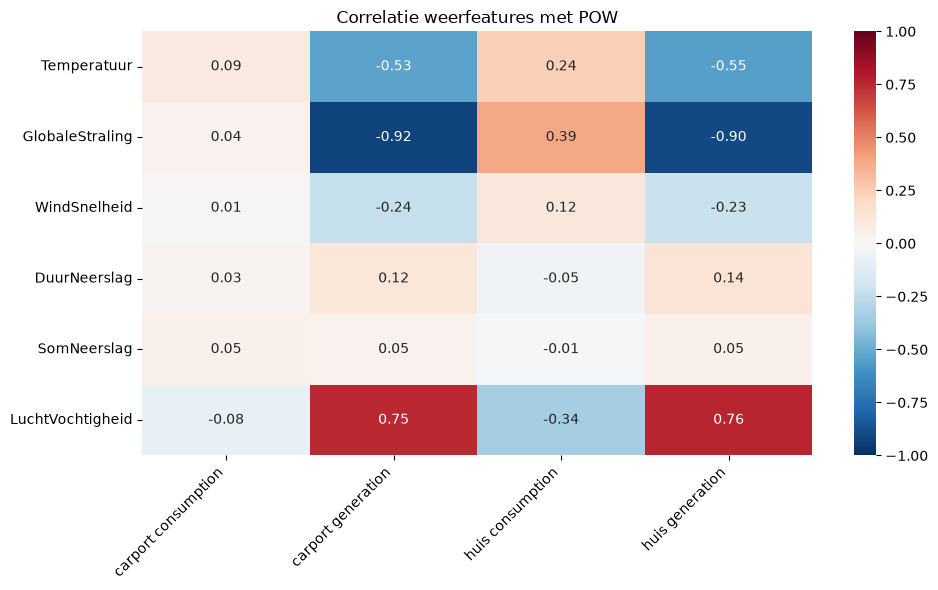

In [11]:
corr_matrix = pd.DataFrame(correlaties, index=weer_features)

plt.figure(figsize=(10, 6))

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)

plt.title("Correlatie weerfeatures met POW")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [12]:
modeldata.head()

,timestamp,location,target_type,pow_w,pow_imputed,is_observed,is_conflict,is_imputed,impute_methode,Windrichting,WindSnelheid,Temperatuur,GlobaleStraling,DuurNeerslag,SomNeerslag,LuchtVochtigheid
0,2024-03-08 01:00:00+01:00,carport,consumption,786.222222,786.222222,True,False,False,NaN,70.0,3.0,0.8,0,0,0.0,90.0
1,2024-03-08 01:05:00+01:00,carport,consumption,3108.181818,3108.181818,True,False,False,NaN,70.0,3.0,0.8,0,0,0.0,90.0
2,2024-03-08 01:10:00+01:00,carport,consumption,3253.111111,3253.111111,True,False,False,NaN,70.0,3.0,0.8,0,0,0.0,90.0
3,2024-03-08 01:15:00+01:00,carport,consumption,3249.264706,3249.264706,True,False,False,NaN,70.0,3.0,0.8,0,0,0.0,90.0
4,2024-03-08 01:20:00+01:00,carport,consumption,1446.435897,1446.435897,True,False,False,NaN,70.0,3.0,0.8,0,0,0.0,90.0


In [13]:
modeldata.to_parquet(DATA_DIR / "forecast_targets_with_weather.parquet", index=False)